<a href="https://colab.research.google.com/github/Andres10-cmd/Andres10-cmd/blob/main/random_forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

                      Decision tree

Accuracy: 0.9444

              precision    recall  f1-score   support

     class_0       1.00      0.92      0.96        12
     class_1       0.88      1.00      0.93        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.94        36
   macro avg       0.96      0.94      0.95        36
weighted avg       0.95      0.94      0.94        36



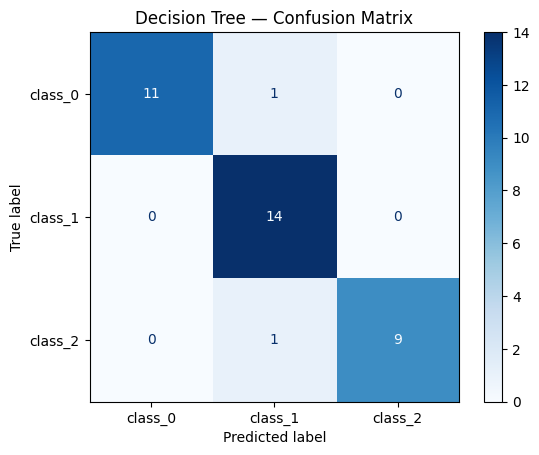

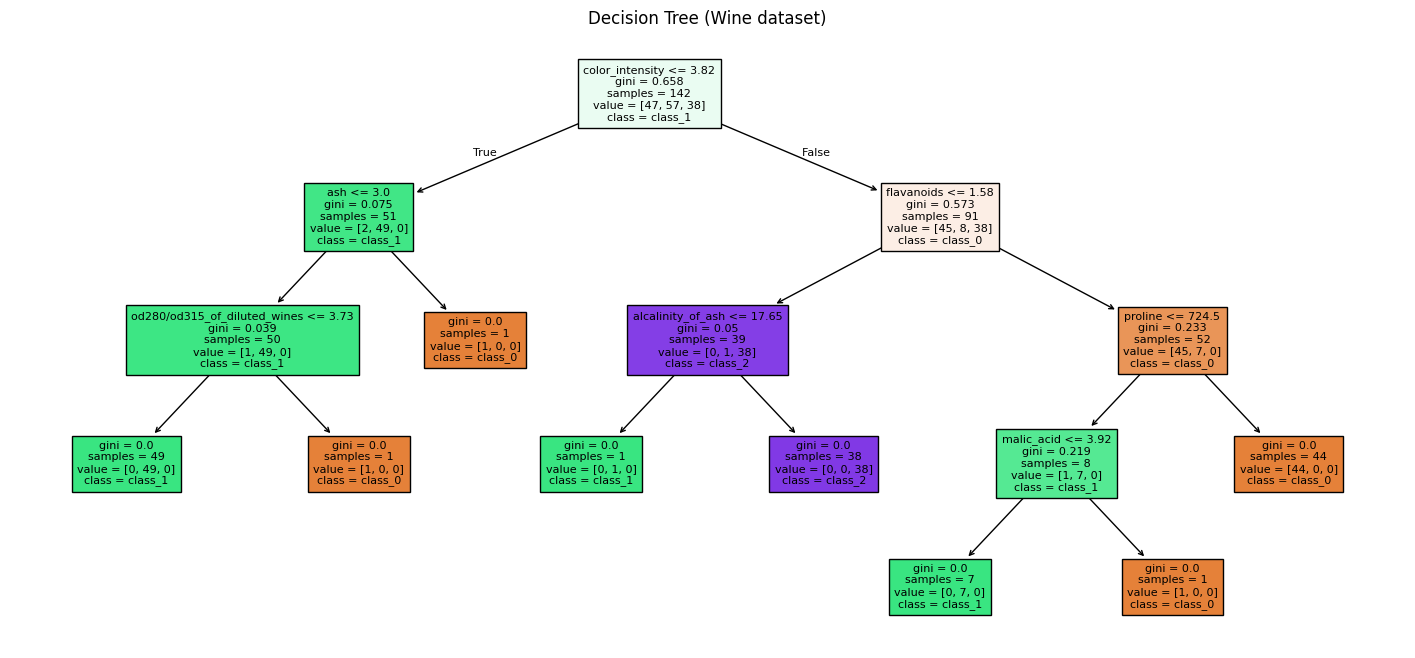


Top features:
 flavanoids                      0.408073
color_intensity                 0.400189
proline                         0.110985
od280/od315_of_diluted_wines    0.020986
alcalinity_of_ash               0.020865
dtype: float64


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# 1. Load the dataset (upload wine_dataset.csv in Colab first)
df = pd.read_csv("wine_dataset.csv")

X = df.drop(columns=["target", "wine_class"])
y = df["target"]

# 2. Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Train the Decision Tree
dt = DecisionTreeClassifier(max_depth=4, random_state=42)
dt.fit(X_train, y_train)

# 4. Predict and evaluate
y_pred = dt.predict(X_test)
acc = accuracy_score(y_test, y_pred)
print(f"Accuracy: {acc:.4f}\n")
print(classification_report(y_test, y_pred, target_names=["class_0", "class_1", "class_2"]))

# 5. Confusion matrix
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["class_0", "class_1", "class_2"]).plot(cmap="Blues")
plt.title("Decision Tree — Confusion Matrix")
plt.show()

# 6. Visualize the tree
plt.figure(figsize=(18, 8))
plot_tree(dt, feature_names=X.columns, class_names=["class_0", "class_1", "class_2"],
          filled=True, fontsize=8)
plt.title("Decision Tree (Wine dataset)")
plt.show()

# 7. Feature importance
importances = pd.Series(dt.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\nTop features:\n", importances.head(5))

                            Support Vector

Accuracy: 0.9722

              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       0.93      1.00      0.97        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



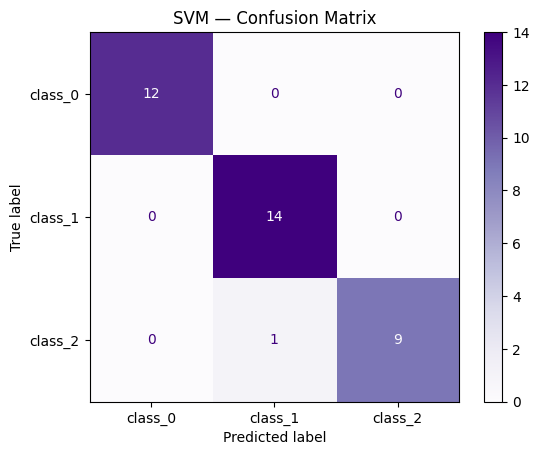

Kernel = linear   -> Accuracy = 0.9444
Kernel = rbf      -> Accuracy = 0.9722
Kernel = poly     -> Accuracy = 0.9444


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# 1. Load the dataset (upload wine_dataset.csv in Colab first)
df = pd.read_csv("wine_dataset.csv")

X = df.drop(columns=["target", "wine_class"])
y = df["target"]

# 2. Train/test split (same split as Decision Tree / Random Forest for a fair comparison)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Scale the features (important for SVM)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Train the SVM
svm = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=42)
svm.fit(X_train_scaled, y_train)

# 5. Predict and evaluate
y_pred = svm.predict(X_test_scaled)
acc = accuracy_score(y_test, y_pred)
print(f"Accuracy: {acc:.4f}\n")
print(classification_report(y_test, y_pred, target_names=["class_0", "class_1", "class_2"]))

# 6. Confusion matrix
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["class_0", "class_1", "class_2"]).plot(cmap="Purples")
plt.title("SVM — Confusion Matrix")
plt.show()

# 7. (Optional) Try different kernels to compare
for kernel in ["linear", "rbf", "poly"]:
    model = SVC(kernel=kernel, random_state=42)
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)
    print(f"Kernel = {kernel:8s} -> Accuracy = {accuracy_score(y_test, preds):.4f}")

                        random222

Number of trees in the forest: 200
Accuracy: 1.0000

              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       1.00      1.00      1.00        14
     class_2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



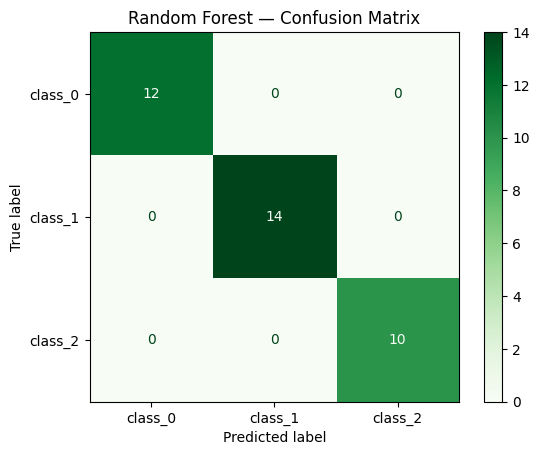

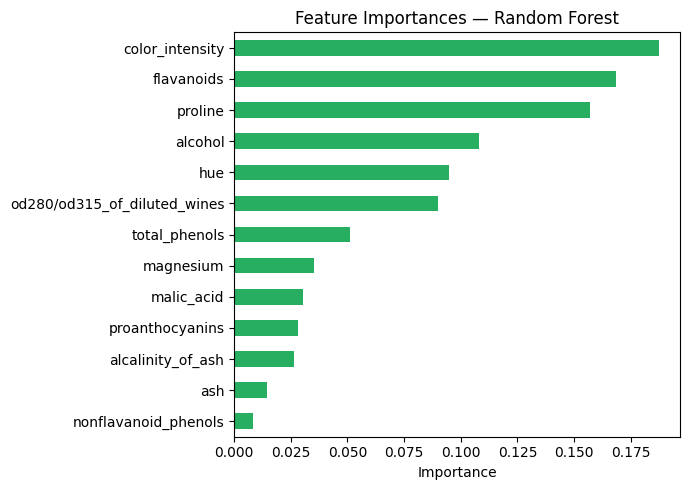


Top features:
 color_intensity    0.187404
flavanoids         0.168373
proline            0.157024
alcohol            0.108171
hue                0.094966
dtype: float64


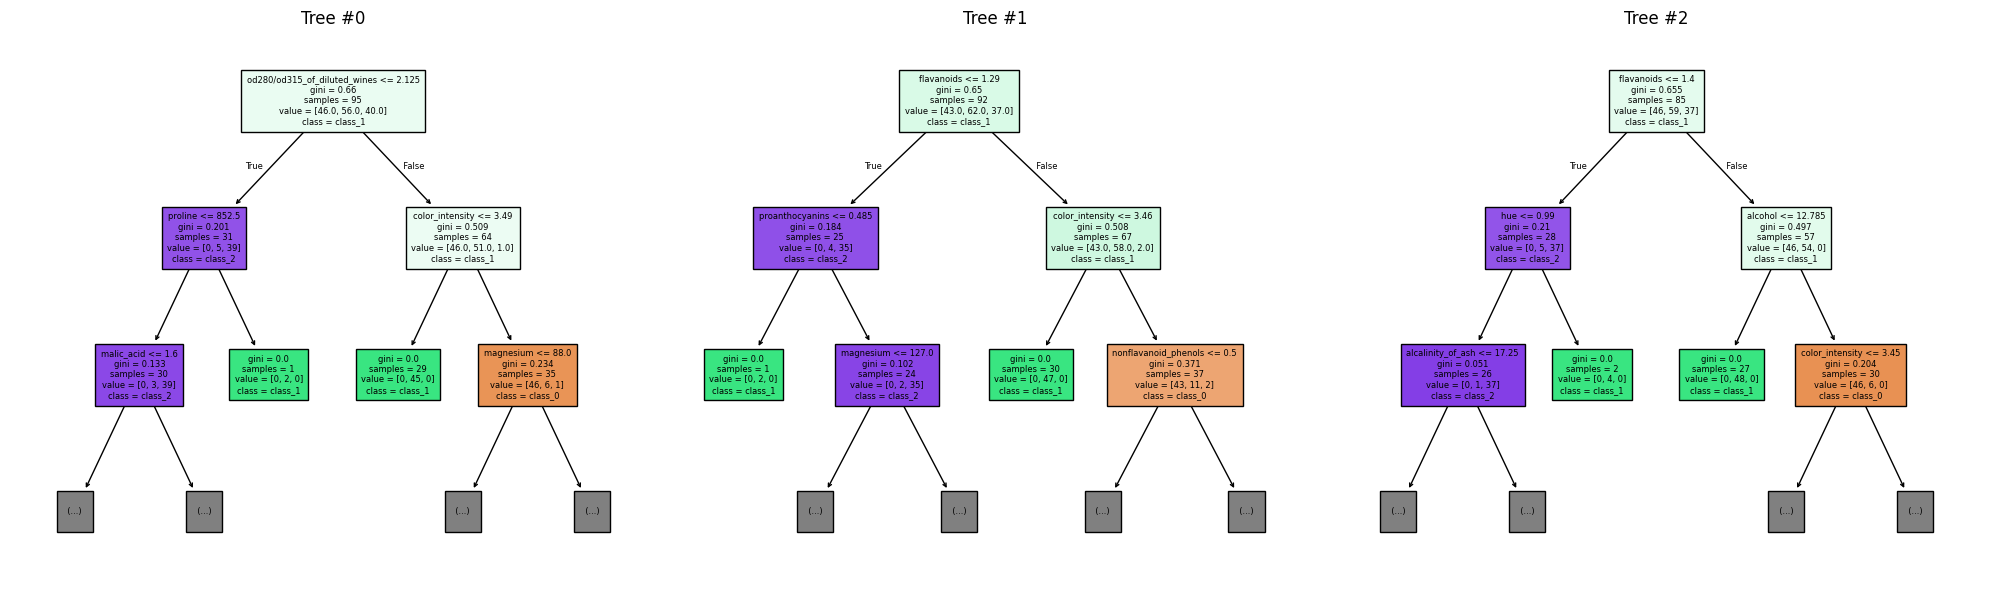

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# 1. Load the dataset (upload wine_dataset.csv in Colab first)
df = pd.read_csv("wine_dataset.csv")

X = df.drop(columns=["target", "wine_class"])
y = df["target"]

# 2. Train/test split (same split as the Decision Tree for a fair comparison)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Train the Random Forest
rf = RandomForestClassifier(n_estimators=200, max_depth=None, random_state=42)
rf.fit(X_train, y_train)

print(f"Number of trees in the forest: {len(rf.estimators_)}")

# 4. Predict and evaluate
y_pred = rf.predict(X_test)
acc = accuracy_score(y_test, y_pred)
print(f"Accuracy: {acc:.4f}\n")
print(classification_report(y_test, y_pred, target_names=["class_0", "class_1", "class_2"]))

# 5. Confusion matrix
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["class_0", "class_1", "class_2"]).plot(cmap="Greens")
plt.title("Random Forest — Confusion Matrix")
plt.show()

# 6. Feature importance (Random Forest's strength over a single tree)
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(7, 5))
importances.sort_values().plot(kind="barh", color="#27ae60")
plt.title("Feature Importances — Random Forest")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

print("\nTop features:\n", importances.head(5))

# 7. Visualize a few individual trees from the forest
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for i, ax in enumerate(axes):
    plot_tree(rf.estimators_[i], feature_names=X.columns,
              class_names=["class_0", "class_1", "class_2"],
              filled=True, fontsize=6, max_depth=2, ax=ax)
    ax.set_title(f"Tree #{i}")
plt.tight_layout()
plt.show()